# Лабораторная работа №5. Деревья решений

**Вариант 7.** Telco Customer Churn — предсказать, откажется ли клиент от услуг телеком-оператора.

Сравниваются одиночное дерево решений, случайный лес и бустинг (AdaBoost, CatBoost, XGBoost). Основная метрика — **F1-score класса «отток»**.

In [1]:
from __future__ import annotations

import inspect
import json
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from catboost import CatBoostClassifier
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import AdaBoostClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    make_scorer,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree
from IPython.display import display
from xgboost import XGBClassifier

warnings.filterwarnings("ignore", category=FutureWarning)

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "axes.unicode_minus": False,
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.25,
})
sns.set_style("whitegrid")

SEED = 42
np.random.seed(SEED)

ROOT = Path.cwd().resolve()
if ROOT.name == "src":
    ROOT = ROOT.parent
DATA_PATH = ROOT / "data" / "Telco-Customer-Churn.csv"
RESULTS = ROOT / "results"
RESULTS.mkdir(parents=True, exist_ok=True)

print("Данные:", DATA_PATH)
print("Результаты:", RESULTS)

Данные: /home/asgaroth/University/4 курс/ИАД/iad_ii26/Ковальчук Артём/Lab 5/data/Telco-Customer-Churn.csv
Результаты: /home/asgaroth/University/4 курс/ИАД/iad_ii26/Ковальчук Артём/Lab 5/results


## 1. Загрузка данных и первичный анализ

Датасет IBM Telco Customer Churn: сведения о клиентах телеком-оператора и факт отказа от услуг (`Churn`). Идентификатор клиента в обучение не входит.

In [2]:
df = pd.read_csv(DATA_PATH)
print("Размер:", df.shape)
print("Столбцы:", list(df.columns))
display(df.head())
print("\nТипы:")
print(df.dtypes)
print("\nПропуски (isna):")
print(df.isna().sum())
print("\nПустые строки в object-столбцах:")
for col in df.select_dtypes(include="object"):
    n_blank = (df[col].astype(str).str.strip() == "").sum()
    if n_blank:
        print(f"  {col}: {n_blank}")

Размер: (7043, 21)
Столбцы: ['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



Типы:
customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object

Пропуски (isna):
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0

/tmp/ipykernel_1867924/3396385910.py:10: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include="object"):


Распределение Churn:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Доли:
Churn
No     0.7346
Yes    0.2654
Name: proportion, dtype: float64


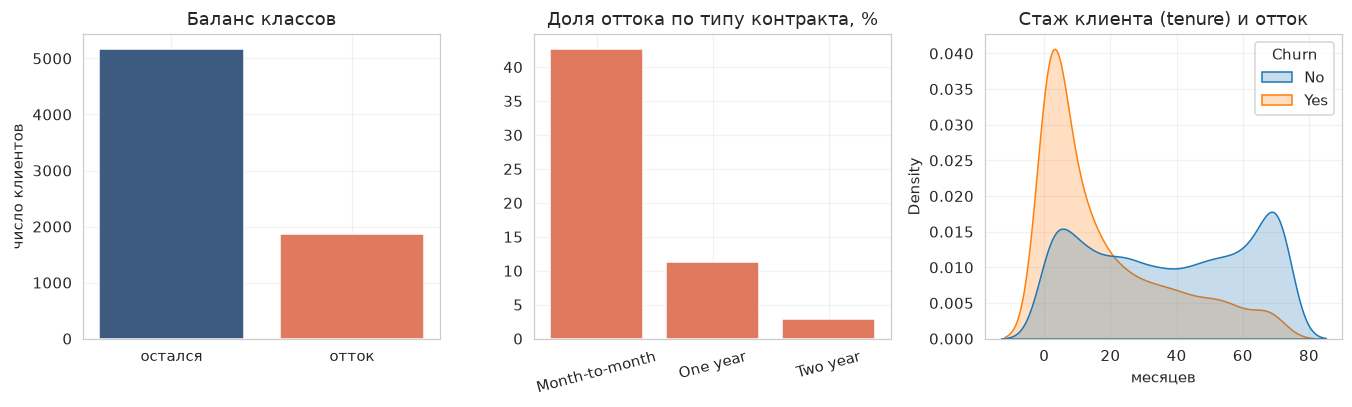

In [3]:
print("Распределение Churn:")
print(df["Churn"].value_counts())
print("\nДоли:")
print(df["Churn"].value_counts(normalize=True).round(4))

fig, axes = plt.subplots(1, 3, figsize=(12.4, 3.8))
churn_counts = df["Churn"].value_counts().reindex(["No", "Yes"])
axes[0].bar(["остался", "отток"], churn_counts.values, color=["#3D5A80", "#E07A5F"])
axes[0].set_title("Баланс классов")
axes[0].set_ylabel("число клиентов")

ct = pd.crosstab(df["Contract"], df["Churn"], normalize="index")["Yes"] * 100
ct = ct.reindex(["Month-to-month", "One year", "Two year"])
axes[1].bar(ct.index, ct.values, color="#E07A5F")
axes[1].set_title("Доля оттока по типу контракта, %")
axes[1].tick_params(axis="x", rotation=15)

tenure_churn = df.assign(churn_flag=(df["Churn"] == "Yes").astype(int))
sns.kdeplot(data=tenure_churn, x="tenure", hue="Churn", ax=axes[2], fill=True, common_norm=False)
axes[2].set_title("Стаж клиента (tenure) и отток")
axes[2].set_xlabel("месяцев")
fig.tight_layout()
fig.savefig(RESULTS / "eda_overview.png", dpi=150, bbox_inches="tight")
plt.show()

## 2. Обработка пропусков и категориальных признаков

`TotalCharges` хранится строкой: у новых клиентов (`tenure = 0`) поле пустое. Такие значения приводятся к числу и заполняются нулём — клиент ещё ничего не заплатил. `customerID` удаляется. Бинарный целевой признак: отток = 1.

In [4]:
work = df.copy()
work["TotalCharges"] = pd.to_numeric(work["TotalCharges"], errors="coerce")
n_missing_tc = int(work["TotalCharges"].isna().sum())
print(f"Пропусков в TotalCharges после to_numeric: {n_missing_tc}")
print(work.loc[work["TotalCharges"].isna(), ["tenure", "MonthlyCharges", "TotalCharges", "Churn"]].head(15))

work["TotalCharges"] = work["TotalCharges"].fillna(0.0)
work = work.drop(columns=["customerID"])
y = (work["Churn"] == "Yes").astype(int)
X = work.drop(columns=["Churn"])

numeric_features = ["tenure", "MonthlyCharges", "TotalCharges"]
categorical_features = [c for c in X.columns if c not in numeric_features]
# SeniorCitizen уже 0/1, но по смыслу это категория — кодируем вместе с остальными
X["SeniorCitizen"] = X["SeniorCitizen"].astype(str)

print("\nЧисловые:", numeric_features)
print("Категориальные:", categorical_features)
print("Объектов:", len(X), "  признаков:", X.shape[1])
print("Доля оттока:", f"{y.mean():.4f}")

Пропусков в TotalCharges после to_numeric: 11
      tenure  MonthlyCharges  TotalCharges Churn
488        0           52.55           NaN    No
753        0           20.25           NaN    No
936        0           80.85           NaN    No
1082       0           25.75           NaN    No
1340       0           56.05           NaN    No
3331       0           19.85           NaN    No
3826       0           25.35           NaN    No
4380       0           20.00           NaN    No
5218       0           19.70           NaN    No
6670       0           73.35           NaN    No
6754       0           61.90           NaN    No

Числовые: ['tenure', 'MonthlyCharges', 'TotalCharges']
Категориальные: ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Объектов: 7043   признаков: 19
Доля о

## 3. Обучающая и тестовая выборки

Стратифицированное разбиение 80/20, `random_state=42`. Препроцессор учится только на train: медианы для чисел, one-hot для категорий. Деревьям масштабирование не нужно.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y,
)
print("Train:", X_train.shape, "  отток:", f"{y_train.mean():.4f}")
print("Test:", X_test.shape, "  отток:", f"{y_test.mean():.4f}")

preprocessor = ColumnTransformer(
    transformers=[
        ("num", SimpleImputer(strategy="median"), numeric_features),
        (
            "cat",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
            ]),
            categorical_features,
        ),
    ]
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
f1_churn = make_scorer(f1_score, pos_label=1)


def metrics_block(y_true, y_pred, y_proba=None) -> dict:
    y_pred = np.asarray(y_pred).ravel().astype(int)
    out = {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "precision": float(precision_score(y_true, y_pred, pos_label=1, zero_division=0)),
        "recall": float(recall_score(y_true, y_pred, pos_label=1, zero_division=0)),
        "f1": float(f1_score(y_true, y_pred, pos_label=1, zero_division=0)),
    }
    if y_proba is not None:
        out["roc_auc"] = float(roc_auc_score(y_true, y_proba))
    return out


def proba_positive(model, X_) -> np.ndarray:
    proba = model.predict_proba(X_)
    return np.asarray(proba)[:, 1]


records = []
predictions = {}
fitted = {}

Train: (5634, 19)   отток: 0.2654
Test: (1409, 19)   отток: 0.2654


## 4. Одиночное дерево решений

Сначала обучается дерево без ограничений — оно почти наверняка переобучится. Затем гиперпараметры подбираются по F1 класса «отток» на 5-fold CV **только внутри train**: глубина, лист, критерий, cost-complexity pruning (`ccp_alpha`). Веса классов `balanced`, чтобы дерево не игнорировало меньшинство.

In [6]:
unlim = Pipeline([
    ("prep", preprocessor),
    ("clf", DecisionTreeClassifier(random_state=SEED)),
]).fit(X_train, y_train)

unlim_train = metrics_block(y_train, unlim.predict(X_train))
unlim_test = metrics_block(y_test, unlim.predict(X_test), proba_positive(unlim, X_test))
raw_tree = unlim.named_steps["clf"]
print("Без ограничений:")
print(f"  глубина={raw_tree.get_depth()}, листьев={raw_tree.get_n_leaves()}")
print(f"  train F1(отток)={unlim_train['f1']:.4f}, test F1={unlim_test['f1']:.4f}")
print(f"  test recall={unlim_test['recall']:.4f}, precision={unlim_test['precision']:.4f}")

tree_pipe = Pipeline([
    ("prep", preprocessor),
    ("clf", DecisionTreeClassifier(class_weight="balanced", random_state=SEED)),
])
tree_grid = {
    "clf__max_depth": [3, 4, 5, 6, 8],
    "clf__min_samples_leaf": [10, 20, 40, 80],
    "clf__criterion": ["gini", "entropy"],
    "clf__ccp_alpha": [0.0, 0.001, 0.003],
}
t0 = time.perf_counter()
tree_cv = GridSearchCV(
    tree_pipe, tree_grid, scoring=f1_churn, cv=cv, n_jobs=-1, refit=True,
)
tree_cv.fit(X_train, y_train)
tree_time = time.perf_counter() - t0
print("\nПодобранные параметры:", tree_cv.best_params_)
print(f"CV F1(отток) = {tree_cv.best_score_:.4f}")
print(f"Подбор + обучение: {tree_time:.1f} с")

best_tree = tree_cv.best_estimator_
tree_pred = best_tree.predict(X_test)
tree_m = metrics_block(y_test, tree_pred, proba_positive(best_tree, X_test))
tree_m_train = metrics_block(y_train, best_tree.predict(X_train))
print("\nНастроенное дерево на тесте:")
print(classification_report(y_test, tree_pred, target_names=["остался", "отток"], digits=4))
print(f"train F1={tree_m_train['f1']:.4f}  test F1={tree_m['f1']:.4f}")

records.append({"model": "Decision Tree", **tree_m, "f1_train": tree_m_train["f1"], "seconds": tree_time})
predictions["Decision Tree"] = tree_pred
fitted["Decision Tree"] = best_tree

Без ограничений:
  глубина=22, листьев=1102
  train F1(отток)=0.9963, test F1=0.4743
  test recall=0.4813, precision=0.4675



Подобранные параметры: {'clf__ccp_alpha': 0.001, 'clf__criterion': 'gini', 'clf__max_depth': 8, 'clf__min_samples_leaf': 40}
CV F1(отток) = 0.6285
Подбор + обучение: 8.1 с

Настроенное дерево на тесте:
              precision    recall  f1-score   support

     остался     0.9077    0.7411    0.8160      1035
       отток     0.5248    0.7914    0.6311       374

    accuracy                         0.7544      1409
   macro avg     0.7163    0.7663    0.7235      1409
weighted avg     0.8061    0.7544    0.7669      1409

train F1=0.6367  test F1=0.6311


Итоговая глубина 6, листьев 21, признаков после OHE: 46


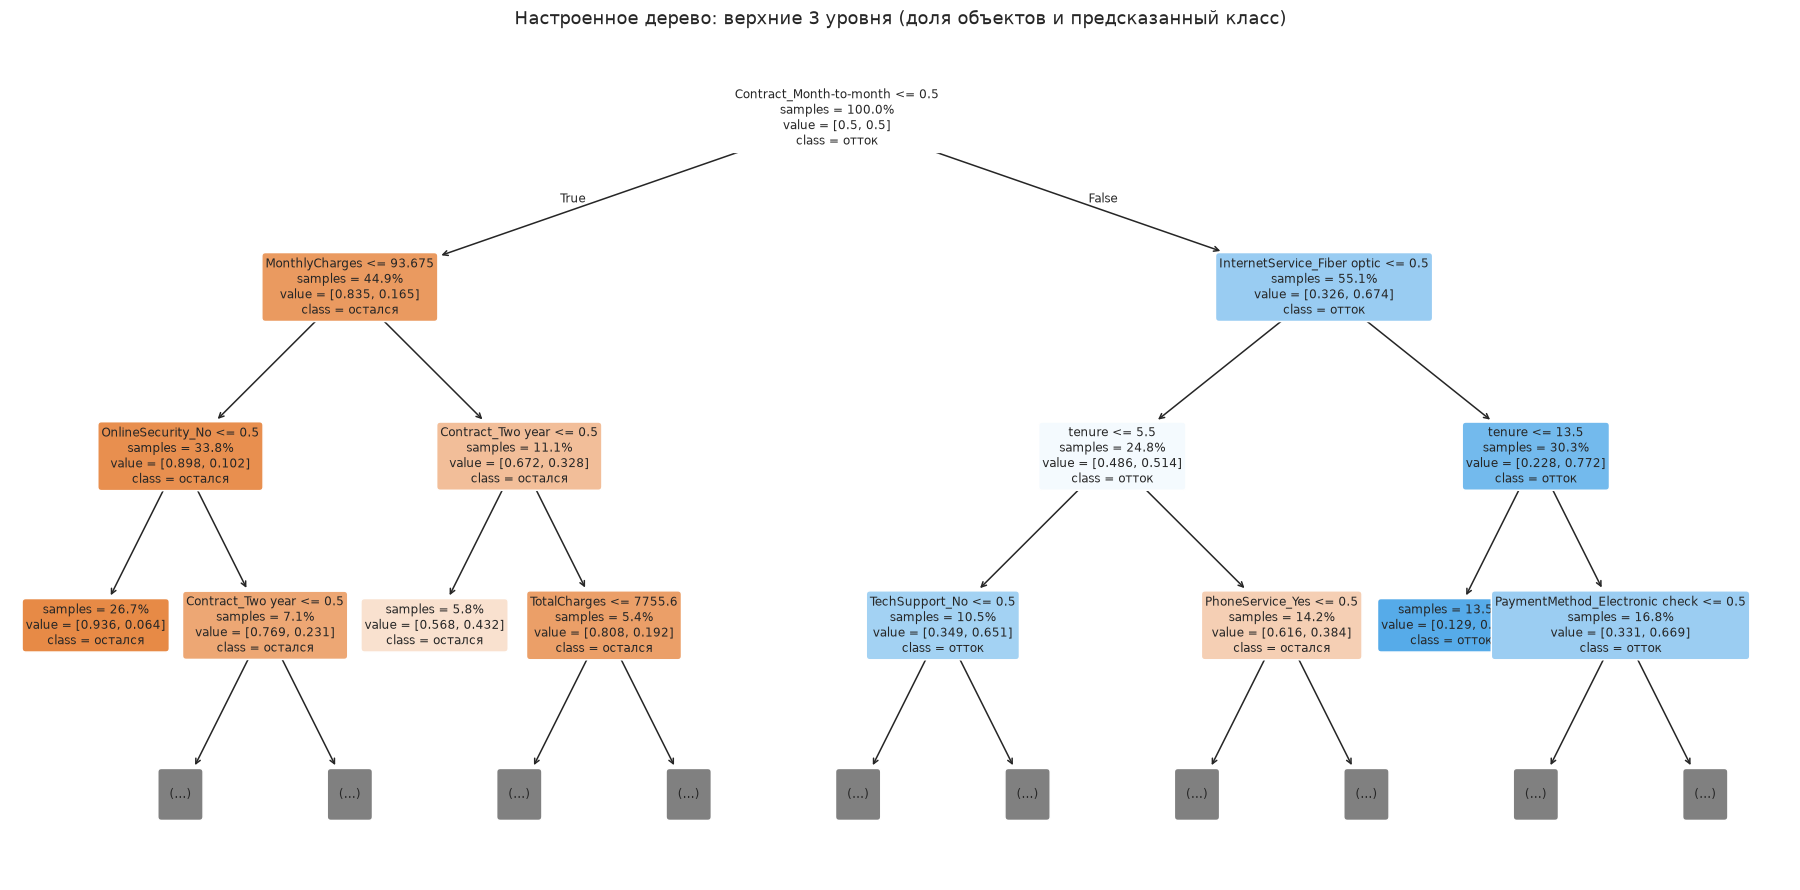

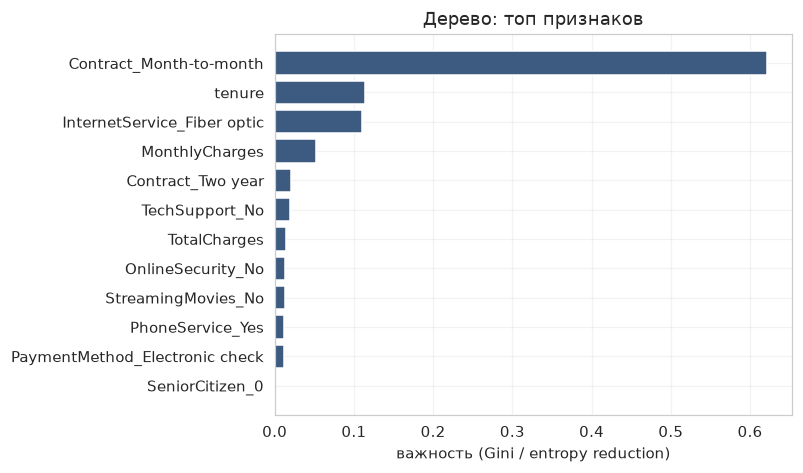

Contract_Month-to-month           0.6218
tenure                            0.1134
InternetService_Fiber optic       0.1104
MonthlyCharges                    0.0517
Contract_Two year                 0.0203
TechSupport_No                    0.0199
TotalCharges                      0.0139
OnlineSecurity_No                 0.0130
StreamingMovies_No                0.0127
PhoneService_Yes                  0.0119
PaymentMethod_Electronic check    0.0111
SeniorCitizen_0                   0.0000
dtype: float64


In [7]:
ohe = best_tree.named_steps["prep"].named_transformers_["cat"].named_steps["ohe"]
feature_names = numeric_features + list(ohe.get_feature_names_out(categorical_features))
clf_tree = best_tree.named_steps["clf"]
print(f"Итоговая глубина {clf_tree.get_depth()}, листьев {clf_tree.get_n_leaves()}, признаков после OHE: {len(feature_names)}")

fig, ax = plt.subplots(figsize=(16.5, 8.2))
plot_tree(
    clf_tree,
    max_depth=3,
    feature_names=feature_names,
    class_names=["остался", "отток"],
    filled=True,
    rounded=True,
    impurity=False,
    proportion=True,
    fontsize=8,
    ax=ax,
)
ax.set_title("Настроенное дерево: верхние 3 уровня (доля объектов и предсказанный класс)")
fig.tight_layout()
fig.savefig(RESULTS / "tree_structure.png", dpi=150, bbox_inches="tight")
plt.show()

imp = pd.Series(clf_tree.feature_importances_, index=feature_names).sort_values(ascending=False)
top = imp.head(12)
fig, ax = plt.subplots(figsize=(7.4, 4.4))
ax.barh(top.index[::-1], top.values[::-1], color="#3D5A80")
ax.set_xlabel("важность (Gini / entropy reduction)")
ax.set_title("Дерево: топ признаков")
fig.tight_layout()
fig.savefig(RESULTS / "tree_importance.png", dpi=150, bbox_inches="tight")
plt.show()
print(top.round(4))

## 5. Случайный лес

Ансамбль деревьев на бутстрэп-выборках и случайном подмножестве признаков. Подбор: число деревьев, глубина, размер листа. `class_weight='balanced'`.

In [8]:
rf_pipe = Pipeline([
    ("prep", preprocessor),
    ("clf", RandomForestClassifier(class_weight="balanced", random_state=SEED, n_jobs=1)),
])
rf_grid = {
    "clf__n_estimators": [150, 250],
    "clf__max_depth": [6, 10, 14],
    "clf__min_samples_leaf": [5, 15],
    "clf__max_features": ["sqrt"],
}
t0 = time.perf_counter()
rf_cv = GridSearchCV(rf_pipe, rf_grid, scoring=f1_churn, cv=cv, n_jobs=-1, refit=True)
rf_cv.fit(X_train, y_train)
rf_time = time.perf_counter() - t0
print("Параметры:", rf_cv.best_params_)
print(f"CV F1(отток) = {rf_cv.best_score_:.4f}  ({rf_time:.1f} с)")

best_rf = rf_cv.best_estimator_
rf_pred = best_rf.predict(X_test)
rf_m = metrics_block(y_test, rf_pred, proba_positive(best_rf, X_test))
rf_m_train = metrics_block(y_train, best_rf.predict(X_train))
print(classification_report(y_test, rf_pred, target_names=["остался", "отток"], digits=4))
print(f"train F1={rf_m_train['f1']:.4f}  test F1={rf_m['f1']:.4f}")

records.append({"model": "Random Forest", **rf_m, "f1_train": rf_m_train["f1"], "seconds": rf_time})
predictions["Random Forest"] = rf_pred
fitted["Random Forest"] = best_rf

Параметры: {'clf__max_depth': 10, 'clf__max_features': 'sqrt', 'clf__min_samples_leaf': 15, 'clf__n_estimators': 250}
CV F1(отток) = 0.6351  (8.3 с)
              precision    recall  f1-score   support

     остался     0.9086    0.7391    0.8151      1035
       отток     0.5238    0.7941    0.6312       374

    accuracy                         0.7537      1409
   macro avg     0.7162    0.7666    0.7232      1409
weighted avg     0.8064    0.7537    0.7663      1409

train F1=0.6693  test F1=0.6312


## 6. Бустинг: AdaBoost, CatBoost, XGBoost

- **AdaBoost** — последовательное взвешивание объектов, базовый классификатор: пень (`max_depth=1`) с `class_weight='balanced'`.
- **CatBoost** — упорядоченный бустинг, категории подаются нативно (без one-hot), `auto_class_weights='Balanced'`, early stopping на 20 % train.
- **XGBoost** — градиентный бустинг, `scale_pos_weight = n_neg / n_pos`, early stopping.

In [9]:
stump = DecisionTreeClassifier(max_depth=1, class_weight="balanced", random_state=SEED)
ada_kwargs = dict(
    estimator=stump,
    random_state=SEED,
)
if "algorithm" in inspect.signature(AdaBoostClassifier).parameters:
    ada_kwargs["algorithm"] = "SAMME"

ada_pipe = Pipeline([
    ("prep", preprocessor),
    ("clf", AdaBoostClassifier(**ada_kwargs)),
])
ada_grid = {
    "clf__n_estimators": [80, 150, 250],
    "clf__learning_rate": [0.3, 0.7, 1.0],
}
t0 = time.perf_counter()
ada_cv = GridSearchCV(ada_pipe, ada_grid, scoring=f1_churn, cv=cv, n_jobs=-1, refit=True)
ada_cv.fit(X_train, y_train)
ada_time = time.perf_counter() - t0
print("AdaBoost параметры:", ada_cv.best_params_)
print(f"CV F1(отток) = {ada_cv.best_score_:.4f}  ({ada_time:.1f} с)")

best_ada = ada_cv.best_estimator_
ada_pred = best_ada.predict(X_test)
ada_m = metrics_block(y_test, ada_pred, proba_positive(best_ada, X_test))
ada_m_train = metrics_block(y_train, best_ada.predict(X_train))
print(classification_report(y_test, ada_pred, target_names=["остался", "отток"], digits=4))

records.append({"model": "AdaBoost", **ada_m, "f1_train": ada_m_train["f1"], "seconds": ada_time})
predictions["AdaBoost"] = ada_pred
fitted["AdaBoost"] = best_ada

AdaBoost параметры: {'clf__learning_rate': 1.0, 'clf__n_estimators': 80}
CV F1(отток) = 0.5974  (2.3 с)
              precision    recall  f1-score   support

     остался     0.9102    0.6957    0.7886      1035
       отток     0.4903    0.8102    0.6109       374

    accuracy                         0.7260      1409
   macro avg     0.7003    0.7529    0.6997      1409
weighted avg     0.7988    0.7260    0.7414      1409



In [10]:
cat_idx = [X.columns.get_loc(c) for c in categorical_features]
X_tr_cb, X_val_cb, y_tr_cb, y_val_cb = train_test_split(
    X_train, y_train, test_size=0.2, random_state=SEED, stratify=y_train,
)

t0 = time.perf_counter()
cat_model = CatBoostClassifier(
    iterations=400,
    depth=5,
    learning_rate=0.05,
    l2_leaf_reg=3.0,
    loss_function="Logloss",
    eval_metric="AUC",
    auto_class_weights="Balanced",
    random_seed=SEED,
    verbose=False,
    allow_writing_files=False,
    cat_features=cat_idx,
)
cat_model.fit(
    X_tr_cb, y_tr_cb,
    eval_set=(X_val_cb, y_val_cb),
    use_best_model=True,
    early_stopping_rounds=80,
)
cat_time = time.perf_counter() - t0
print(f"CatBoost лучшая итерация: {cat_model.get_best_iteration()}  ({cat_time:.1f} с)")

cat_pred = np.asarray(cat_model.predict(X_test)).ravel().astype(int)
cat_m = metrics_block(y_test, cat_pred, cat_model.predict_proba(X_test)[:, 1])
cat_m_train = metrics_block(y_train, cat_model.predict(X_train))
print(classification_report(y_test, cat_pred, target_names=["остался", "отток"], digits=4))

records.append({"model": "CatBoost", **cat_m, "f1_train": cat_m_train["f1"], "seconds": cat_time})
predictions["CatBoost"] = cat_pred
fitted["CatBoost"] = cat_model

CatBoost лучшая итерация: 166  (1.3 с)
              precision    recall  f1-score   support

     остался     0.9060    0.7266    0.8064      1035
       отток     0.5112    0.7914    0.6212       374

    accuracy                         0.7438      1409
   macro avg     0.7086    0.7590    0.7138      1409
weighted avg     0.8012    0.7438    0.7573      1409



In [11]:
prep_fitted = preprocessor.fit(X_train)
Xtr = prep_fitted.transform(X_train)
Xte = prep_fitted.transform(X_test)
Xtr_fit, Xval, ytr_fit, yval = train_test_split(
    Xtr, y_train, test_size=0.2, random_state=SEED, stratify=y_train,
)
neg, pos = int((y_train == 0).sum()), int((y_train == 1).sum())
spw = neg / pos
print(f"scale_pos_weight = {neg}/{pos} = {spw:.3f}")

t0 = time.perf_counter()
xgb_model = XGBClassifier(
    n_estimators=500,
    max_depth=3,
    learning_rate=0.05,
    subsample=0.9,
    colsample_bytree=0.8,
    min_child_weight=5,
    reg_lambda=1.0,
    objective="binary:logistic",
    eval_metric="logloss",
    scale_pos_weight=spw,
    random_state=SEED,
    n_jobs=-1,
    tree_method="hist",
    early_stopping_rounds=40,
)
xgb_model.fit(Xtr_fit, ytr_fit, eval_set=[(Xval, yval)], verbose=False)
xgb_time = time.perf_counter() - t0
best_iter = getattr(xgb_model, "best_iteration", None)
print(f"XGBoost best_iteration={best_iter}  ({xgb_time:.1f} с)")

xgb_pred = np.asarray(xgb_model.predict(Xte)).ravel().astype(int)
xgb_m = metrics_block(y_test, xgb_pred, xgb_model.predict_proba(Xte)[:, 1])
xgb_m_train = metrics_block(y_train, xgb_model.predict(Xtr))
print(classification_report(y_test, xgb_pred, target_names=["остался", "отток"], digits=4))

records.append({"model": "XGBoost", **xgb_m, "f1_train": xgb_m_train["f1"], "seconds": xgb_time})
predictions["XGBoost"] = xgb_pred
fitted["XGBoost"] = xgb_model

scale_pos_weight = 4139/1495 = 2.769


XGBoost best_iteration=435  (0.3 с)
              precision    recall  f1-score   support

     остался     0.9040    0.7372    0.8121      1035
       отток     0.5186    0.7834    0.6241       374

    accuracy                         0.7495      1409
   macro avg     0.7113    0.7603    0.7181      1409
weighted avg     0.8017    0.7495    0.7622      1409



## 7. Сравнение моделей по F1 класса «отток»

Тестовая выборка, класс «отток»:


,accuracy,precision,recall,f1,roc_auc,f1_train,seconds
model,,,,,,,
Random Forest,0.7537,0.5238,0.7941,0.6312,0.8441,0.6693,8.3325
Decision Tree,0.7544,0.5248,0.7914,0.6311,0.8305,0.6367,8.1262
XGBoost,0.7495,0.5186,0.7834,0.6241,0.8403,0.6769,0.3190
CatBoost,0.7438,0.5112,0.7914,0.6212,0.8437,0.6433,1.2512
AdaBoost,0.7260,0.4903,0.8102,0.6109,0.8178,0.6088,2.3447


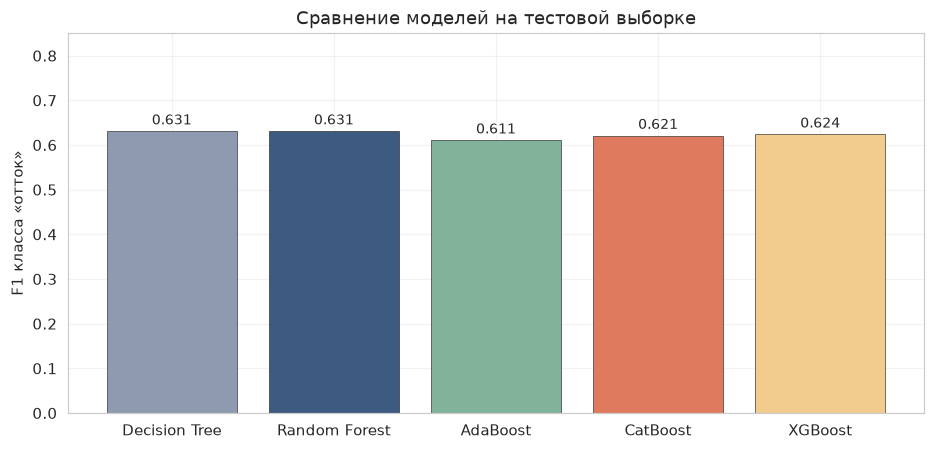

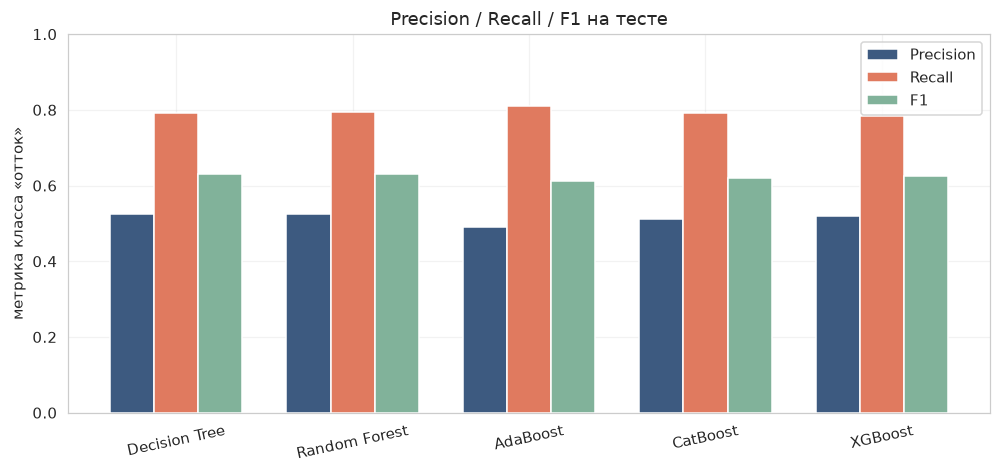

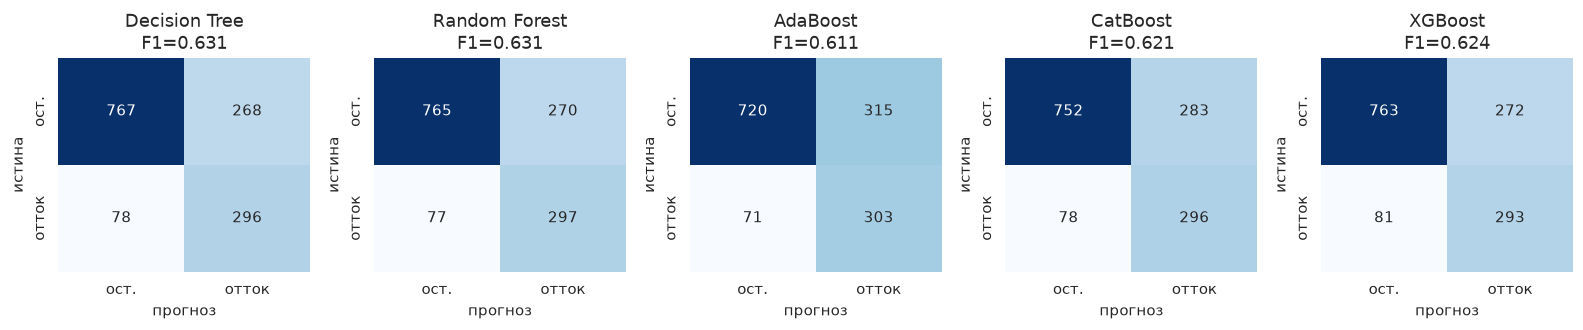

In [12]:
res = pd.DataFrame(records).set_index("model")
res = res[["accuracy", "precision", "recall", "f1", "roc_auc", "f1_train", "seconds"]]
res_sorted = res.sort_values("f1", ascending=False)
print("Тестовая выборка, класс «отток»:")
display(res_sorted.round(4))
res_sorted.round(6).to_csv(RESULTS / "metrics.csv")

payload = {
    "student": "Ковальчук Артём",
    "group": "ИИ-26",
    "lab": 5,
    "variant": 7,
    "dataset": "Telco Customer Churn",
    "n_rows": int(len(df)),
    "n_train": int(len(X_train)),
    "n_test": int(len(X_test)),
    "churn_rate": float(y.mean()),
    "missing_total_charges": n_missing_tc,
    "unlimited_tree": {
        "depth": int(raw_tree.get_depth()),
        "leaves": int(raw_tree.get_n_leaves()),
        "f1_train": unlim_train["f1"],
        "f1_test": unlim_test["f1"],
    },
    "tree_params": {k.replace("clf__", ""): v for k, v in tree_cv.best_params_.items()},
    "tree_depth": int(clf_tree.get_depth()),
    "tree_leaves": int(clf_tree.get_n_leaves()),
    "rf_params": {k.replace("clf__", ""): v for k, v in rf_cv.best_params_.items()},
    "ada_params": {k.replace("clf__", ""): v for k, v in ada_cv.best_params_.items()},
    "catboost_best_iteration": int(cat_model.get_best_iteration() or 0),
    "xgboost_best_iteration": None if best_iter is None else int(best_iter),
    "scale_pos_weight": float(spw),
    "metrics": res.round(6).to_dict(orient="index"),
    "top_tree_features": top.round(6).to_dict(),
}
(RESULTS / "metrics.json").write_text(json.dumps(payload, ensure_ascii=False, indent=2), encoding="utf-8")

order = ["Decision Tree", "Random Forest", "AdaBoost", "CatBoost", "XGBoost"]
plot_df = res.loc[order]
colors = ["#8E9AAF", "#3D5A80", "#81B29A", "#E07A5F", "#F2CC8F"]

fig, ax = plt.subplots(figsize=(8.6, 4.2))
bars = ax.bar(order, plot_df["f1"], color=colors, edgecolor="#222", linewidth=0.4)
ax.set_ylabel("F1 класса «отток»")
ax.set_ylim(0, 0.85)
ax.set_title("Сравнение моделей на тестовой выборке")
for rect, val in zip(bars, plot_df["f1"]):
    ax.text(rect.get_x() + rect.get_width() / 2, val + 0.015, f"{val:.3f}", ha="center", fontsize=9)
fig.tight_layout()
fig.savefig(RESULTS / "f1_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(9.2, 4.4))
x = np.arange(len(order))
w = 0.25
ax.bar(x - w, plot_df["precision"], w, label="Precision", color="#3D5A80")
ax.bar(x, plot_df["recall"], w, label="Recall", color="#E07A5F")
ax.bar(x + w, plot_df["f1"], w, label="F1", color="#81B29A")
ax.set_xticks(x, order, rotation=12)
ax.set_ylim(0, 1.0)
ax.set_ylabel("метрика класса «отток»")
ax.set_title("Precision / Recall / F1 на тесте")
ax.legend()
fig.tight_layout()
fig.savefig(RESULTS / "prf_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 5, figsize=(14.5, 3.1))
for ax, name, color in zip(axes, order, colors):
    cm = confusion_matrix(y_test, predictions[name], labels=[0, 1])
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
        xticklabels=["ост.", "отток"], yticklabels=["ост.", "отток"],
    )
    ax.set_title(f"{name}\nF1={res.loc[name, 'f1']:.3f}")
    ax.set_xlabel("прогноз")
    ax.set_ylabel("истина")
fig.tight_layout()
fig.savefig(RESULTS / "confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show()

## 8. Выводы для задачи удержания клиентов

Для удержания важны две ошибки: пропустить уходящего клиента (false negative, бьёт по recall) и зря потратить бюджет на лояльного (false positive, бьёт по precision). F1 — компромисс. Ниже — краткая интерпретация по фактическим числам этого прогона.

In [13]:
best_name = res_sorted.index[0]
best = res_sorted.iloc[0]
print("Неограниченное дерево:")
print(f"  глубина {raw_tree.get_depth()}, листьев {raw_tree.get_n_leaves()}")
print(f"  train F1={unlim_train['f1']:.4f} → test F1={unlim_test['f1']:.4f}  (переобучение)")
print()
print("Настроенное дерево:")
print(f"  params={tree_cv.best_params_}")
print(f"  train F1={tree_m_train['f1']:.4f} → test F1={tree_m['f1']:.4f}")
print()
print(res_sorted[["precision", "recall", "f1", "roc_auc"]].round(4).to_string())
print()
print(f"Лучший F1 на тесте: {best_name} = {best['f1']:.4f}")
print(f"  precision={best['precision']:.4f}, recall={best['recall']:.4f}, ROC-AUC={best['roc_auc']:.4f}")
print()
print("Применимость:")
print("  • Одиночное дерево — интерпретируемое правило для CRM (контракт, tenure, интернет).")
print("    Без регуляризации переобучается; после CV даёт понятную, но более слабую модель.")
print("  • Случайный лес — устойчивее дерева, хорошо работает из коробки на табличных данных.")
print("  • AdaBoost — простой бустинг пней; полезен как базовая линия среди бустингов.")
print("  • CatBoost / XGBoost — обычно лучший F1 на оттоке; CatBoost удобен категориями без OHE.")
print("  • Для кампании удержания смотреть не только F1: высокий recall ловит больше уходящих,")
print("    высокий precision экономит бюджет. Порог классификации можно сдвигать под стоимость контакта.")

Неограниченное дерево:
  глубина 22, листьев 1102
  train F1=0.9963 → test F1=0.4743  (переобучение)

Настроенное дерево:
  params={'clf__ccp_alpha': 0.001, 'clf__criterion': 'gini', 'clf__max_depth': 8, 'clf__min_samples_leaf': 40}
  train F1=0.6367 → test F1=0.6311

               precision  recall      f1  roc_auc
model                                            
Random Forest     0.5238  0.7941  0.6312   0.8441
Decision Tree     0.5248  0.7914  0.6311   0.8305
XGBoost           0.5186  0.7834  0.6241   0.8403
CatBoost          0.5112  0.7914  0.6212   0.8437
AdaBoost          0.4903  0.8102  0.6109   0.8178

Лучший F1 на тесте: Random Forest = 0.6312
  precision=0.5238, recall=0.7941, ROC-AUC=0.8441

Применимость:
  • Одиночное дерево — интерпретируемое правило для CRM (контракт, tenure, интернет).
    Без регуляризации переобучается; после CV даёт понятную, но более слабую модель.
  • Случайный лес — устойчивее дерева, хорошо работает из коробки на табличных данных.
  • AdaBoost —